In [1]:
from lightning.pytorch import Trainer
from torch.utils.data import DataLoader

from torchgeo.datamodules import InriaAerialImageLabelingDataModule
#from torchgeo.datasets import CDL, Landsat7, Landsat8, VHR10, stack_samples
from torchgeo.datasets import Sentinel2 
#from torchgeo.samplers import RandomPatchSampler
from torchgeo.tasks import ChangeDetection 

c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
#import os
#import tempfile

import lightning as L
import matplotlib.pyplot as plt
import torch
from lightning.pytorch import Trainer
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import TensorBoardLogger

from torchgeo.datamodules import OSCD100DataModule
from torchgeo.datasets import OSCD100
from torchgeo.tasks import ChangeDetection

torch.set_float32_matmul_precision('medium')
L.seed_everything(0, workers=True)

Seed set to 0


0

In [3]:
# Setup

from pathlib import Path

PROJECT_DIR = Path.cwd()
PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

STUDY_AREA = "Nepal, Syabru Besi"
TARGET_CRS = "EPSG:32645"  # UTM zone 45N

print(f"Project directory: {PROJECT_DIR}")
print(f"Study area: {STUDY_AREA}")
print(f"Target CRS: {TARGET_CRS}")

#define the output paths
train_path_s2 = PROCESSED_DATA_DIR / 's2_sub_train' 
val_path_s2 = PROCESSED_DATA_DIR / 's2_sub_val'
test_path_s2 = PROCESSED_DATA_DIR / 's2_sub_test'

train_path_s1 = PROCESSED_DATA_DIR / 's1_sub_train' 
val_path_s1 = PROCESSED_DATA_DIR / 's1_sub_val'
test_path_s1 = PROCESSED_DATA_DIR / 's1_sub_test'

Project directory: c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project
Study area: Nepal, Syabru Besi
Target CRS: EPSG:32645


set up class for my change detection tiles

In [4]:
from pathlib import Path
import rasterio
import torch
from torch.utils.data import Dataset

class ChangeDetectionTiles(Dataset):
    def __init__(self, before_root, after_root, mask_root, tile_size=256, stride=256, bands=("B04", "B03", "B02")):
        self.before_root = Path(before_root)
        self.after_root = Path(after_root)
        self.mask_root = Path(mask_root)
        self.tile_size = tile_size
        self.stride = stride
        self.bands = bands

        self.scenes = sorted([p.name for p in self.before_root.iterdir() if p.is_dir()])
        self.index = []

        for scene in self.scenes:
            with rasterio.open(self.before_root / scene / f"{bands[0]}.tif") as src:
                h, w = src.height, src.width

            for row in range(0, h - tile_size + 1, stride):
                for col in range(0, w - tile_size + 1, stride):
                    self.index.append((scene, row, col))

    def __len__(self):
        return len(self.index)

    def __getitem__(self, idx):
        scene, row, col = self.index[idx]

        before_arrays = []
        after_arrays = []

        for band in self.bands:
            with rasterio.open(self.before_root / scene / f"{band}.tif") as src:
                before_patch = src.read(1, window=((row, row + self.tile_size), (col, col + self.tile_size)))
            with rasterio.open(self.after_root / scene / f"{band}.tif") as src:
                after_patch = src.read(1, window=((row, row + self.tile_size), (col, col + self.tile_size)))

            before_arrays.append(torch.from_numpy(before_patch))
            after_arrays.append(torch.from_numpy(after_patch))

        with rasterio.open(self.mask_root / f"{scene}.tif") as src:
            mask = src.read(1, window=((row, row + self.tile_size), (col, col + self.tile_size)))

        # Stack the before and after arrays into a single tensor
        before = torch.stack(before_arrays, dim=0)
        after = torch.stack(after_arrays, dim=0)

        # Return a dictionary containing the stacked images, mask, scene name, row, and column
        return {
            "image": torch.stack([before, after], dim=0).float(),  # [2, C, H, W]
            "mask": torch.from_numpy(mask).float().unsqueeze(0),  # Convert mask to float tensor and add a channel dimension
            "scene": scene,
            "row": row,
            "col": col,
        }


In [5]:
#collate function that stacks the before and after images into a single tensor
def collate_fn(batch):
    return {
        "image": torch.stack([x["image"] for x in batch]),  # [B, 2, C, H, W]
        "mask": torch.stack([x["mask"] for x in batch]),    # [B, H, W]
        "scene": [x["scene"] for x in batch],
        "row": [x["row"] for x in batch],
        "col": [x["col"] for x in batch],
    }


In [34]:
#dataset_tile_size = 256
#dataset_stride = 256
sample_tile_size = 64
sample_stride = 32
bands = ["B04", "B03", "B02"]  # Red, Green, Blue bands for Sentinel-2

#create dataset for change detection using the ChangeDetectionTiles class
#dataset = ChangeDetectionTiles(RAW_DATA_DIR / 's2_tg' / 't1', RAW_DATA_DIR / 's2_tg' / 't2', RAW_DATA_DIR / 's2_tg' / 'mask', tile_size=dataset_tile_size, stride=dataset_stride, bands=bands)

train_ds = ChangeDetectionTiles(train_path_s2 / 't1', train_path_s2 / 't2', train_path_s2 / 'mask', tile_size=sample_tile_size, stride=sample_stride, bands=bands)
val_ds = ChangeDetectionTiles(val_path_s2 / 't1', val_path_s2 / 't2', val_path_s2 / 'mask', tile_size=sample_tile_size, stride=sample_stride, bands=bands)
test_ds = ChangeDetectionTiles(test_path_s2 / 't1', test_path_s2 / 't2', test_path_s2 / 'mask', tile_size=sample_tile_size, stride=sample_stride, bands=bands)

print(f"Number of training samples: {len(train_ds)}")
print(f"Number of validation samples: {len(val_ds)}")
print(f"Number of test samples: {len(test_ds)}")

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, collate_fn=collate_fn) #increase batch size later, for now just a small batch size to test the code
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False, collate_fn=collate_fn) #increase batch size later, for now just a small batch size to test the code
test_loader = DataLoader(test_ds, batch_size=8, shuffle=False, collate_fn=collate_fn) #increase batch size later, for now just a small batch size to test the code


Number of training samples: 286
Number of validation samples: 99
Number of test samples: 99


In [35]:
#updated for new collate function that stacks the before and after images into a single tensor
#sanity check, takes a moment:
#full scenes are 10'980x10980 pixels
#torch:Size(batch_size, num_bands, tile_size, tile_size)

import rasterio
batch = next(iter(train_loader))

print(type(batch))
print(batch.keys())
print("image:", batch["image"].shape, batch["image"].dtype)
print("mask:  ", batch["mask"].shape, batch["mask"].dtype)
print("scene: ", batch["scene"][:5])
print("row:   ", batch["row"][:5])
print("col:   ", batch["col"][:5])


<class 'dict'>
dict_keys(['image', 'mask', 'scene', 'row', 'col'])
image: torch.Size([8, 2, 3, 64, 64]) torch.float32
mask:   torch.Size([8, 1, 64, 64]) torch.float32
scene:  ['scene001', 'scene001', 'scene001', 'scene001', 'scene001']
row:    [800, 768, 544, 32, 288]
col:    [0, 128, 96, 128, 160]


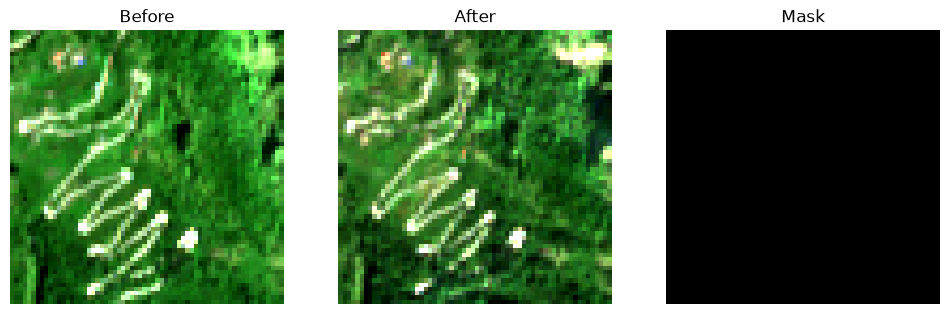

In [36]:
#visually compare a sample
import numpy as np
import matplotlib.pyplot as plt

def stretch_percentile(img, p_low=2, p_high=98):
    lo = np.percentile(img, p_low)
    hi = np.percentile(img, p_high)
    img = np.clip(img, lo, hi)
    return (img - lo) / (hi - lo + 1e-6)

i = 0
before = batch["image"][i, 0].permute(1, 2, 0).numpy().astype(np.float32)
after = batch["image"][i, 1].permute(1, 2, 0).numpy().astype(np.float32)
mask = batch["mask"][i, 0].numpy()

before_rgb = before[:, :, :3]
after_rgb = after[:, :, :3]

before_rgb = stretch_percentile(before_rgb, 2, 98)
after_rgb = stretch_percentile(after_rgb, 2, 98)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(before_rgb)
ax[0].set_title("Before")
ax[1].imshow(after_rgb)
ax[1].set_title("After")
ax[2].imshow(mask, cmap="gray")
ax[2].set_title("Mask")
for a in ax:
    a.axis("off")
plt.show()


attempt at change detection with my S2 data

In [52]:
from torchgeo.models import ResNet50_Weights

weights = ResNet50_Weights.SENTINEL2_RGB_MOCO

task = ChangeDetection(
    model='fcsiamconc',
    backbone='resnet50',
    weights=weights,  # sentinel-2 RGB pre-trained ResNet50 encoder
    freeze_backbone=True,  # only fine-tune the decoder head
    loss='bce',
    pos_weight=torch.tensor([10.0]),  # upweight the rare change class
    in_channels=3,  # RGB bands
    lr=0.0001,
)

filename = "sampletiles_64x64_stride32fcsiamconc_resnet50"

In [38]:
"""
task = ChangeDetection(
    model='btc',
    backbone='swin_tiny',
    weights=True,  # use Cityscapes-pretrained Swin-Tiny encoder
    freeze_backbone=True,  # only fine-tune the decoder head
    loss='bce',
    pos_weight=torch.tensor([10.0]),  # upweight the rare change class
    in_channels=3,  # RGB bands
    lr=0.0001,
)
"""

"\ntask = ChangeDetection(\n    model='btc',\n    backbone='swin_tiny',\n    weights=True,  # use Cityscapes-pretrained Swin-Tiny encoder\n    freeze_backbone=True,  # only fine-tune the decoder head\n    loss='bce',\n    pos_weight=torch.tensor([10.0]),  # upweight the rare change class\n    in_channels=3,  # RGB bands\n    lr=0.0001,\n)\n"

In [ ]:
from pytorch_lightning.loggers import CSVLogger

# Define where to save the logs
logger = CSVLogger(save_dir= RESULTS_DIR / "logs/", name=filename)


trainer = Trainer(max_epochs = 10, log_every_n_steps=1, logger=logger)
trainer.fit(model=task, train_dataloaders=train_loader, val_dataloaders=val_loader)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model         │ FCSiamConc        │ 40.4 M │ train │     0 │
│ 1 │ criterion     │ BCEWithLogitsLoss │      0 │ train │     0 │
│ 2 │ train_metrics │ MetricCollection  │      0 │ train │     0 │
│ 3 │ val_metrics   │ MetricCollection  │      0 │ train │     0 │
│ 4 │ test_metrics  │ MetricCollection  │      0 │ train │     0 │
└───┴───────────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 16.8 M                                                                                           
Non-trainable params: 23.5 M                                                                                       
Total params: 40.4 M                                                                                               
Total estimated model params size (MB): 161.419                                                                    
Modules in train mode: 257                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\lightning\pytorch\utilities\data.py:79: Trying to 
infer the `batch_size` from an ambiguous collection. The batch size we found is 3. To avoid any miscalculations, 
use `self.log(..., batch_size=batch_size)`.

`Trainer.fit` stopped: `max_epochs=10` reached.


In [40]:
## evalute the model

ckpt_path = 'best'
trainer.test(model = task, dataloaders = test_loader, ckpt_path=ckpt_path)

Restoring states from the checkpoint path at c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\results\logs\sampletiles_64x64_stride32fcsiamconc_resnet50\version_0\checkpoints\epoch=9-step=360.ckpt
Loaded model weights from the checkpoint at c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\results\logs\sampletiles_64x64_stride32fcsiamconc_resnet50\version_0\checkpoints\epoch=9-step=360.ckpt


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│   test_AverageAccuracy    │    0.9828485250473022     │
│    test_AverageF1Score    │    0.9135627746582031     │
│ test_AverageJaccardIndex  │    0.8408794403076172     │
│   test_AveragePrecision   │    0.8719396591186523     │
│    test_AverageRecall     │    0.9593589305877686     │
│   test_OverallAccuracy    │    0.9828485250473022     │
│    test_OverallF1Score    │    0.9135627746582031     │
│ test_OverallJaccardIndex  │    0.8408794403076172     │
│   test_OverallPrecision   │    0.8719396591186523     │
│    test_OverallRecall     │    0.9593589305877686     │
│         test_loss         │    0.2468632161617279     │
└───────────────────────────┴───────────────────────────┘

[{'test_loss': 0.2468632161617279,
  'test_AverageAccuracy': 0.9828485250473022,
  'test_AverageF1Score': 0.9135627746582031,
  'test_AverageJaccardIndex': 0.8408794403076172,
  'test_AveragePrecision': 0.8719396591186523,
  'test_AverageRecall': 0.9593589305877686,
  'test_OverallAccuracy': 0.9828485250473022,
  'test_OverallF1Score': 0.9135627746582031,
  'test_OverallJaccardIndex': 0.8408794403076172,
  'test_OverallPrecision': 0.8719396591186523,
  'test_OverallRecall': 0.9593589305877686}]

In [41]:
preds = trainer.predict(model = task, dataloaders = test_loader, ckpt_path=ckpt_path)

Restoring states from the checkpoint path at c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\results\logs\sampletiles_64x64_stride32fcsiamconc_resnet50\version_0\checkpoints\epoch=9-step=360.ckpt
Loaded model weights from the checkpoint at c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\results\logs\sampletiles_64x64_stride32fcsiamconc_resnet50\version_0\checkpoints\epoch=9-step=360.ckpt


Output()

In [54]:
#save as tif (new version)
ref_path = test_path_s2 / "t1" / "scene001" / "B02.tif"

# Read the reference raster's size and georeferencing first
with rasterio.open(ref_path) as src:
    H, W = src.height, src.width
    transform = src.transform
    crs = src.crs
    profile = src.profile.copy()

canvas = np.zeros((H, W), dtype=np.float32)
count = np.zeros((H, W), dtype=np.float32)

pred_idx = 0
for batch in test_loader:
    preds_batch = preds[pred_idx]          # [B, 1, h, w]
    pred_idx += 1

    for i in range(preds_batch.shape[0]):
        row = int(batch["row"][i])
        col = int(batch["col"][i])
        patch = preds_batch[i, 0].detach().cpu().numpy()
        h, w = patch.shape

        # Clip at the raster edges in case a tile runs past them
        r1, c1 = min(row + h, H), min(col + w, W)
        ph, pw = r1 - row, c1 - col

        canvas[row:r1, col:c1] += patch[:ph, :pw]
        count[row:r1, col:c1] += 1

canvas = canvas / np.maximum(count, 1)

profile.update(
    dtype="float32",
    count=1,
    height=H,
    width=W,
    transform=transform,
    crs=crs,
    compress="lzw",
    nodata=None,
)

out_path = RESULTS_DIR / "predictions" / f"pred_{filename}.tif"
out_path.parent.mkdir(parents=True, exist_ok=True)
with rasterio.open(out_path, "w", **profile) as dst:
    dst.write(canvas.astype(np.float32), 1)


pred: (327, 397) gt: (327, 397) t2: (327, 397, 3)
IoU: 0.842  F1: 0.914


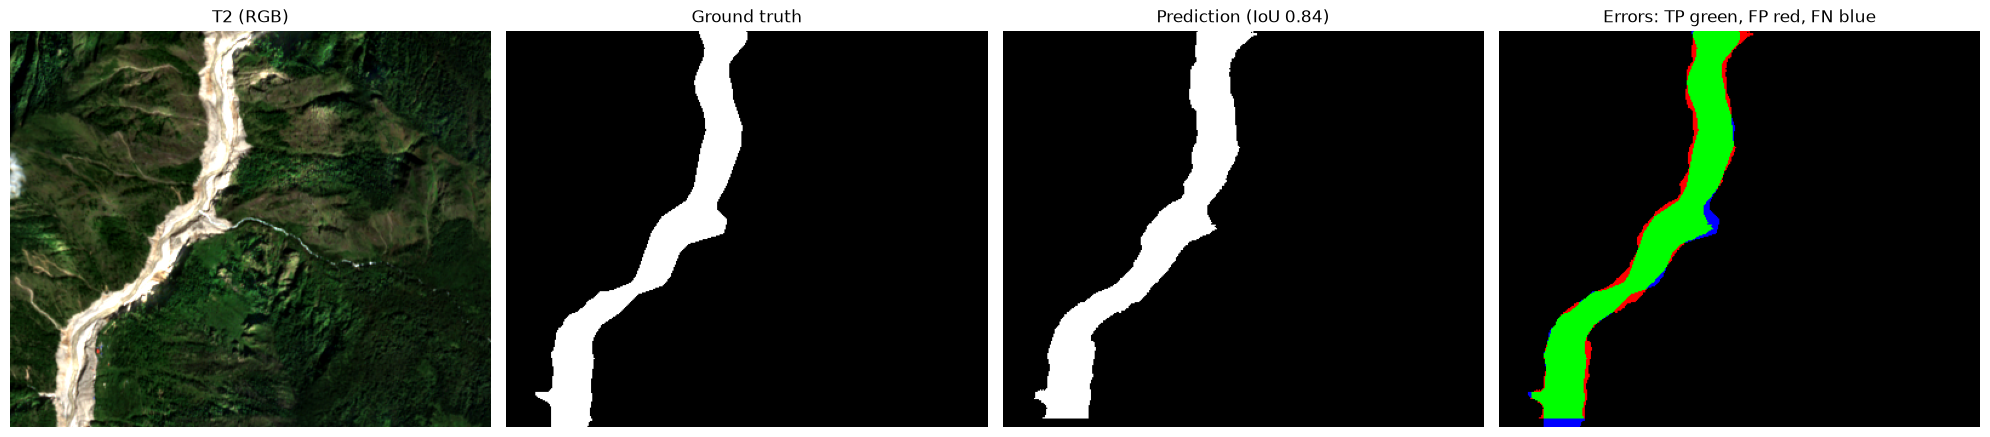

In [55]:
pred_path = out_path

with rasterio.open(pred_path) as src:
    pred_prob = src.read(1)

with rasterio.open(gt_path) as src:
    gt = src.read(1)

with rasterio.open(t2_path) as src:
    t2 = src.read([1, 2, 3]).transpose(1, 2, 0).astype(np.float32)

print("pred:", pred_prob.shape, "gt:", gt.shape, "t2:", t2.shape)

# If the subset is smaller than the full prediction, crop the prediction to the
# same window using the georeferencing (the subset's bounds must lie inside the prediction)
if pred_prob.shape != gt.shape:
    from rasterio.windows import from_bounds
    with rasterio.open(pred_path) as pred_src, rasterio.open(gt_path) as gt_src:
        win = from_bounds(*gt_src.bounds, transform=pred_src.transform)
        pred_prob = pred_src.read(1, window=win, boundless=False)
    print("Cropped prediction to:", pred_prob.shape)

assert pred_prob.shape == gt.shape == t2.shape[:2], "Shapes still differ after cropping"

pred = (pred_prob >= 0.5).astype(np.uint8)
gt_bin = (gt > 0).astype(np.uint8)

# Metrics on the change class
tp = np.sum((pred == 1) & (gt_bin == 1))
fp = np.sum((pred == 1) & (gt_bin == 0))
fn = np.sum((pred == 0) & (gt_bin == 1))
iou = tp / max(tp + fp + fn, 1)
f1 = 2 * tp / max(2 * tp + fp + fn, 1)
print(f"IoU: {iou:.3f}  F1: {f1:.3f}")

# Stretch T2 for display
lo, hi = np.percentile(t2, 2), np.percentile(t2, 98)
t2_vis = np.clip((t2 - lo) / (hi - lo + 1e-6), 0, 1)

# Error map: TP green, FP red, FN blue
error = np.zeros((*gt_bin.shape, 3))
error[(pred == 1) & (gt_bin == 1)] = [0, 1, 0]
error[(pred == 1) & (gt_bin == 0)] = [1, 0, 0]
error[(pred == 0) & (gt_bin == 1)] = [0, 0, 1]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(t2_vis);                  axes[0].set_title("T2 (RGB)")
axes[1].imshow(gt_bin, cmap="gray");     axes[1].set_title("Ground truth")
axes[2].imshow(pred, cmap="gray");       axes[2].set_title(f"Prediction (IoU {iou:.2f})")
axes[3].imshow(error);                   axes[3].set_title("Errors: TP green, FP red, FN blue")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
#save as tif (old version)
"""
# get scene size from the original raster
H, W = 10980, 10980   # or read from raster metadata
canvas = np.zeros((H, W), dtype=np.float32)
count = np.zeros((H, W), dtype=np.float32)

pred_idx = 0
for batch in test_loader:
    preds_batch = preds[pred_idx]   # [B, 1, 32, 32]
    pred_idx += 1

    for i in range(preds_batch.shape[0]):
        row = batch["row"][i]
        col = batch["col"][i]
        patch = preds_batch[i, 0].detach().cpu().numpy()

        canvas[row:row+sample_tile_size, col:col+sample_tile_size] += patch
        count[row:row+sample_tile_size, col:col+sample_tile_size] += 1

canvas = canvas / np.maximum(count, 1)


with rasterio.open(test_path_s2 / "t1" / "scene001" / "B02.tif") as src:
    transform = src.transform
    crs = src.crs

    profile = src.profile.copy()
    profile.update(
    dtype="float32",
    count=1,
    height=canvas.shape[0],
    width=canvas.shape[1],
    transform=transform,
    compress="lzw",
)

with rasterio.open(RESULTS_DIR / "predictions" / "pred_sampletiles_64x64_fcsiamconc_resnet50.tif", "w", **profile) as dst:
    dst.write(canvas.astype(np.float32), 1)
"""


## change detection for s1 radar data

In [ ]:
#dataset_tile_size = 256
#dataset_stride = 256
sample_tile_size = 64
sample_stride = 64
bands = ["vv", "vh"]  # Vertical transmit, Horizontal receive bands for SAR data

#create dataset for change detection using the ChangeDetectionTiles class
#dataset = ChangeDetectionTiles(RAW_DATA_DIR / 's1_tg' / 't1', RAW_DATA_DIR / 's1_tg' / 't2', RAW_DATA_DIR / 's1_tg' / 'mask', tile_size=dataset_tile_size, stride=dataset_stride, bands=bands)

train_ds = ChangeDetectionTiles(train_path_s1 / 't1', train_path_s1 / 't2', train_path_s1 / 'mask', tile_size=sample_tile_size, stride=sample_stride, bands=bands)
val_ds = ChangeDetectionTiles(val_path_s1 / 't1', val_path_s1 / 't2', val_path_s1 / 'mask', tile_size=sample_tile_size, stride=sample_stride, bands=bands)
test_ds = ChangeDetectionTiles(test_path_s1 / 't1', test_path_s1 / 't2', test_path_s1 / 'mask', tile_size=sample_tile_size, stride=sample_stride, bands=bands)

print(f"Number of training samples: {len(train_ds)}")
print(f"Number of validation samples: {len(val_ds)}")
print(f"Number of test samples: {len(test_ds)}")

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, collate_fn=collate_fn) #increase batch size later, for now just a small batch size to test the code
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False, collate_fn=collate_fn) #increase batch size later, for now just a small batch size to test the code
test_loader = DataLoader(test_ds, batch_size=8, shuffle=False, collate_fn=collate_fn) #increase batch size later, for now just a small batch size to test the code


Number of training samples: 78
Number of validation samples: 30
Number of test samples: 30


In [33]:
#updated for new collate function that stacks the before and after images into a single tensor
#sanity check, takes a moment:
#full scenes are 10'980x10980 pixels
#torch:Size(batch_size, num_bands, tile_size, tile_size)

import rasterio
batch = next(iter(train_loader))

print(type(batch))
print(batch.keys())
print("image:", batch["image"].shape, batch["image"].dtype)
print("mask:  ", batch["mask"].shape, batch["mask"].dtype)
print("scene: ", batch["scene"][:5])
print("row:   ", batch["row"][:5])
print("col:   ", batch["col"][:5])

<class 'dict'>
dict_keys(['image', 'mask', 'scene', 'row', 'col'])
image: torch.Size([8, 2, 2, 64, 64]) torch.float32
mask:   torch.Size([8, 1, 64, 64]) torch.float32
scene:  ['scene001', 'scene001', 'scene001', 'scene001', 'scene001']
row:    [640, 256, 128, 384, 768]
col:    [128, 256, 128, 128, 64]


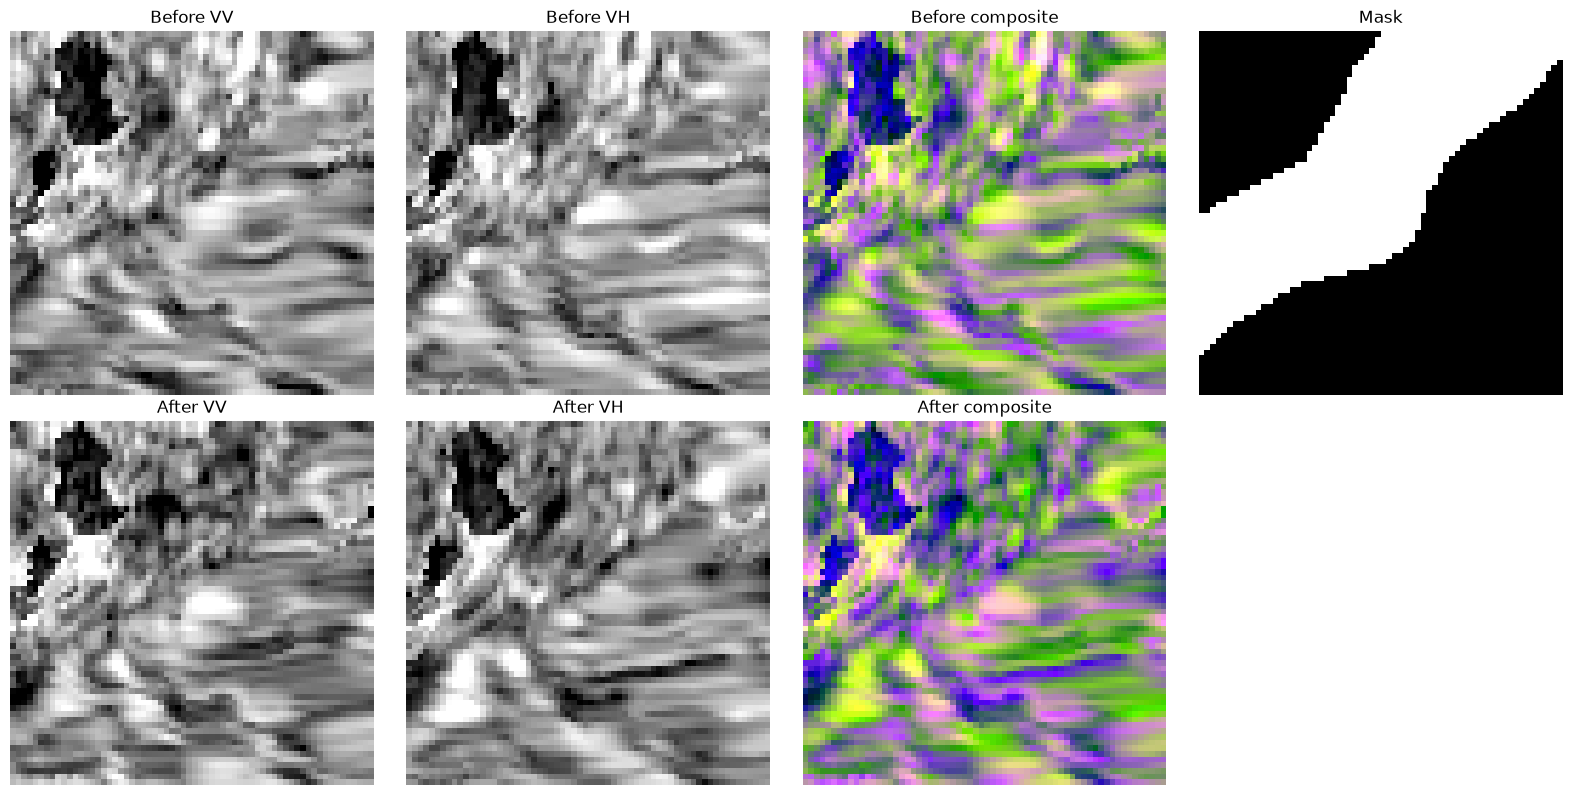

In [ ]:
#visually inspect a sample

import numpy as np
import matplotlib.pyplot as plt

def to_db(img, eps=1e-6):
    # Linear backscatter -> decibels; nodata/zeros are clipped to avoid log(0)
    img = np.nan_to_num(img, nan=eps)
    return 10 * np.log10(np.clip(img, eps, None))

def stretch_percentile(img, p_low=2, p_high=98):
    lo = np.percentile(img, p_low)
    hi = np.percentile(img, p_high)
    img = np.clip(img, lo, hi)
    return (img - lo) / (hi - lo + 1e-6)

i = 0
# Channel order assumed: 0 = VH, 1 = VV (swap if your batch is ordered differently)
before = batch["image"][i, 0].permute(1, 2, 0).numpy().astype(np.float32)  # (H, W, 2)
after = batch["image"][i, 1].permute(1, 2, 0).numpy().astype(np.float32)
mask = batch["mask"][i, 0].numpy()

before_db = to_db(before)
after_db = to_db(after)

# Single-band greyscale stretches
before_vh = stretch_percentile(before_db[:, :, 0])
before_vv = stretch_percentile(before_db[:, :, 1])
after_vh = stretch_percentile(after_db[:, :, 0])
after_vv = stretch_percentile(after_db[:, :, 1])

# False-colour composite: R = VV, G = VH, B = VV - VH (dB difference)
def composite(db):
    r = stretch_percentile(db[:, :, 1])
    g = stretch_percentile(db[:, :, 0])
    b = stretch_percentile(db[:, :, 1] - db[:, :, 0])
    return np.dstack([r, g, b])

before_rgb = composite(before_db)
after_rgb = composite(after_db)

fig, ax = plt.subplots(2, 4, figsize=(16, 8))

# Row 1: before
ax[0, 0].imshow(before_vv, cmap="gray"); ax[0, 0].set_title("Before VV")
ax[0, 1].imshow(before_vh, cmap="gray"); ax[0, 1].set_title("Before VH")
ax[0, 2].imshow(before_rgb);             ax[0, 2].set_title("Before composite")

# Row 2: after
ax[1, 0].imshow(after_vv, cmap="gray"); ax[1, 0].set_title("After VV")
ax[1, 1].imshow(after_vh, cmap="gray"); ax[1, 1].set_title("After VH")
ax[1, 2].imshow(after_rgb);             ax[1, 2].set_title("After composite")

# Mask in the top-right panel, bottom-right left empty
ax[0, 3].imshow(mask, cmap="gray"); ax[0, 3].set_title("Mask")
ax[1, 3].axis("off")

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.show()


In [66]:
from torchgeo.models import ResNet50_Weights
#ResNet50_Weights.SENTINEL1_ALL_MOCO
weights = ResNet50_Weights.SENTINEL1_ALL_MOCO  # or another SENTINEL1 entry

In [ ]:
#adapt the task for SAR data with 2 input channels (VV and VH)
task_s1 = ChangeDetection(
    model='unet',
    backbone='resnet50',
    weights= weights,  # Path to the pre-trained weights from https://github.com/zhu-xlab/SSL4EO-S12
    freeze_backbone=True,  # only fine-tune the decoder head
    loss='bce',
    pos_weight=torch.tensor([10.0]),  # upweight the rare change class
    in_channels=2,  # SAR bands (VV and VH)
    lr=0.0001,
)

Downloading: "https://hf.co/torchgeo/resnet50_sentinel1_all_moco/resolve/e79862c667853c10a709bdd77ea8ffbad0e0f1cf/resnet50_sentinel1_all_moco-906e4356.pth" to C:\Users\herol/.cache\torch\hub\checkpoints\resnet50_sentinel1_all_moco-906e4356.pth


100%|██████████| 90.0M/90.0M [00:06<00:00, 15.0MB/s]


RuntimeError: Error(s) in loading state_dict for ResNetEncoder:
	size mismatch for conv1.weight: copying a param with shape torch.Size([64, 2, 7, 7]) from checkpoint, the shape in current model is torch.Size([64, 4, 7, 7]).

In [ ]:
print(task_s1.model.encoder.conv1)  # expect in_channels=4

Conv2d(4, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)


In [75]:
task_s1 = ChangeDetection(
    model='unet',
    backbone='resnet50',
    weights=None,  # no task checkpoint; load the backbone manually below
    freeze_backbone=False,  # fine-tune the encoder
    loss='bce',
    pos_weight=torch.tensor([10.0]),
    in_channels=2,
    lr=0.0001,
)

ckpt = torch.load(PROJECT_DIR / "scripts" / "B2_rn50_moco_0099.pth", map_location="cpu")
raw = ckpt.get("state_dict", ckpt)

sd = {}
for k, v in raw.items():
    k = k.replace("module.", "").replace("encoder_q.", "")
    sd[k] = v

w = sd["conv1.weight"]                       # (64, 2, 7, 7)
sd["conv1.weight"] = torch.cat([w, w], dim=1) / 2   # (64, 4, 7, 7)

missing = task_s1.model.encoder.load_state_dict(sd, strict=False)
print("missing:", missing)
#print("unexpected:", unexpected)


missing: None


In [87]:
# same code with suggestions from claude
import types

task_s1 = ChangeDetection(
    model='unet',
    backbone='resnet50',
    weights=None,            # no task checkpoint; load the backbone manually below
    freeze_backbone=False,   # fine-tune the encoder
    loss='bce',
    pos_weight=torch.tensor([10.0]),
    in_channels=2,
    lr=0.0001,               # used for the decoder/head
)

ckpt = torch.load(PROJECT_DIR / "scripts" / "B2_rn50_moco_0099.pth", map_location="cpu")
raw = ckpt.get("state_dict", ckpt)

sd = {}
for k, v in raw.items():
    k = k.replace("module.", "").replace("encoder_q.", "")
    sd[k] = v

w = sd["conv1.weight"]                              # (64, 2, 7, 7)
sd["conv1.weight"] = torch.cat([w, w], dim=1) / 2   # (64, 4, 7, 7)

result = task_s1.model.encoder.load_state_dict(sd, strict=False)
#print("missing:", result.missing_keys)
#print("unexpected:", result.unexpected_keys)

# Differential learning rates: encoder fine-tunes slowly, head learns faster
def configure_optimizers(self):
    enc_params = list(self.model.encoder.parameters())
    enc_ids = {id(p) for p in enc_params}
    head_params = [p for p in self.parameters() if id(p) not in enc_ids]
    return torch.optim.AdamW([
        {"params": enc_params, "lr": 1e-5},
        {"params": head_params, "lr": 1e-4},
    ])

task_s1.configure_optimizers = types.MethodType(configure_optimizers, task_s1)


In [88]:
#fit the model using the new dataset and dataloaders but the same task
from pytorch_lightning.loggers import CSVLogger

# Define where to save the logs
logger = CSVLogger(save_dir= RESULTS_DIR / "logs/", name="sampletiles_64x64_s1")


trainer = Trainer(max_epochs = 20, log_every_n_steps=1, logger=logger)
trainer.fit(model=task_s1, train_dataloaders=train_loader, val_dataloaders=val_loader)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model         │ Unet              │ 32.5 M │ train │     0 │
│ 1 │ criterion     │ BCEWithLogitsLoss │      0 │ train │     0 │
│ 2 │ train_metrics │ MetricCollection  │      0 │ train │     0 │
│ 3 │ val_metrics   │ MetricCollection  │      0 │ train │     0 │
│ 4 │ test_metrics  │ MetricCollection  │      0 │ train │     0 │
└───┴───────────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 32.5 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 32.5 M                                                                                               
Total estimated model params size (MB): 130.097                                                                    
Modules in train mode: 257                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.p
y:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of 
the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.

c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.p
y:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value 
of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.

`Trainer.fit` stopped: `max_epochs=20` reached.


In [89]:
## evalute the model

ckpt_path = 'best'
trainer.test(model = task_s1, dataloaders = test_loader, ckpt_path=ckpt_path)

Restoring states from the checkpoint path at c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\results\logs\sampletiles_64x64_s1\version_9\checkpoints\epoch=19-step=200.ckpt
Loaded model weights from the checkpoint at c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\results\logs\sampletiles_64x64_s1\version_9\checkpoints\epoch=19-step=200.ckpt


Output()

c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│   test_AverageAccuracy    │    0.9284993410110474     │
│    test_AverageF1Score    │    0.5200480818748474     │
│ test_AverageJaccardIndex  │    0.35139524936676025    │
│   test_AveragePrecision   │    0.6219782829284668     │
│    test_AverageRecall     │    0.44682249426841736    │
│   test_OverallAccuracy    │    0.9284993410110474     │
│    test_OverallF1Score    │    0.5200480818748474     │
│ test_OverallJaccardIndex  │    0.35139524936676025    │
│   test_OverallPrecision   │    0.6219782829284668     │
│    test_OverallRecall     │    0.44682249426841736    │
│         test_loss         │    0.9838588237762451     │
└───────────────────────────┴───────────────────────────┘

[{'test_loss': 0.9838588237762451,
  'test_AverageAccuracy': 0.9284993410110474,
  'test_AverageF1Score': 0.5200480818748474,
  'test_AverageJaccardIndex': 0.35139524936676025,
  'test_AveragePrecision': 0.6219782829284668,
  'test_AverageRecall': 0.44682249426841736,
  'test_OverallAccuracy': 0.9284993410110474,
  'test_OverallF1Score': 0.5200480818748474,
  'test_OverallJaccardIndex': 0.35139524936676025,
  'test_OverallPrecision': 0.6219782829284668,
  'test_OverallRecall': 0.44682249426841736}]

In [90]:
preds = trainer.predict(model = task_s1, dataloaders = test_loader, ckpt_path=ckpt_path)

Restoring states from the checkpoint path at c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\results\logs\sampletiles_64x64_s1\version_9\checkpoints\epoch=19-step=200.ckpt
Loaded model weights from the checkpoint at c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\results\logs\sampletiles_64x64_s1\version_9\checkpoints\epoch=19-step=200.ckpt


Output()

c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


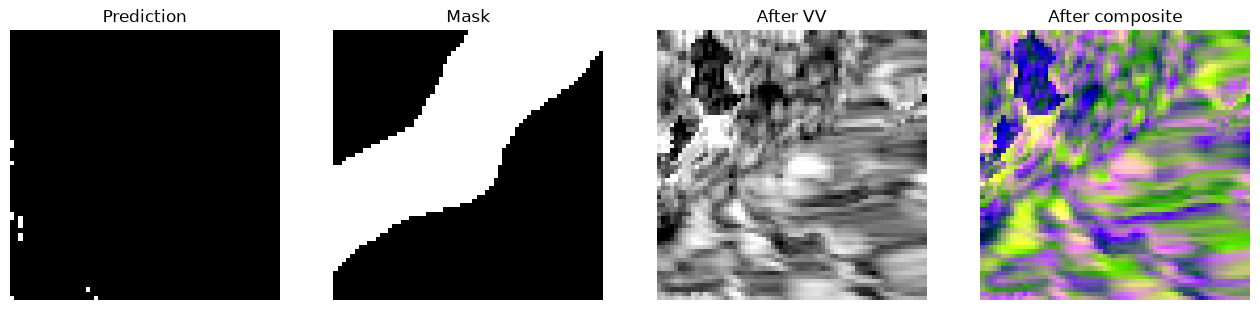

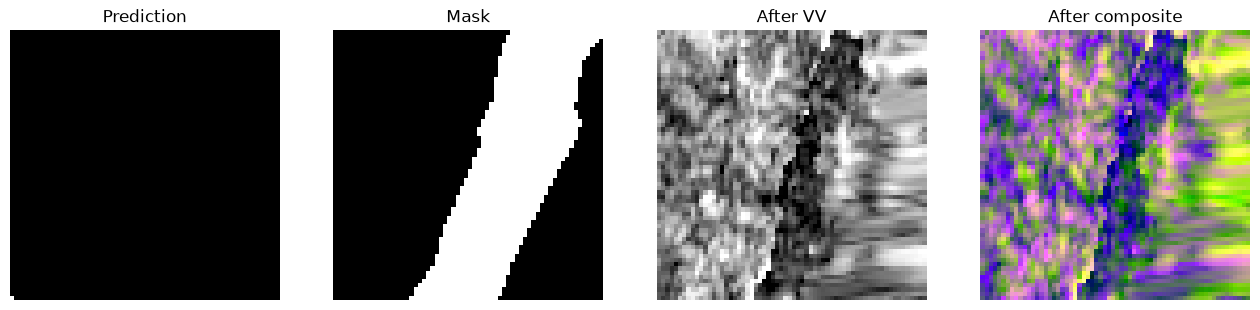

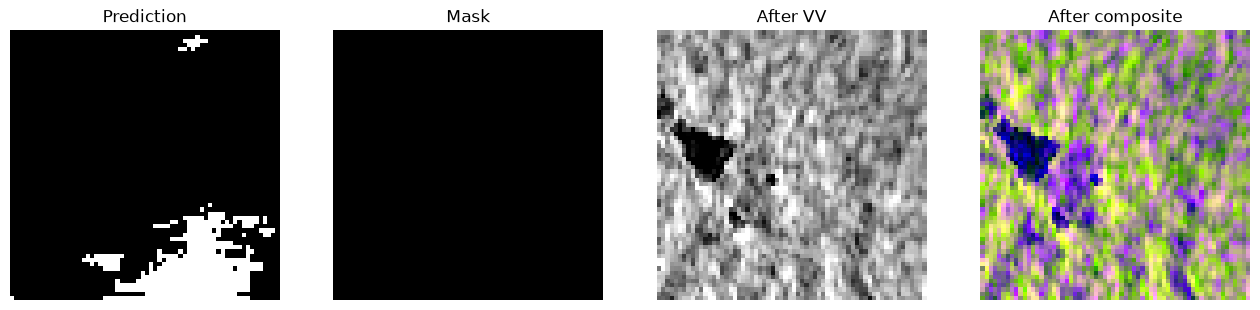

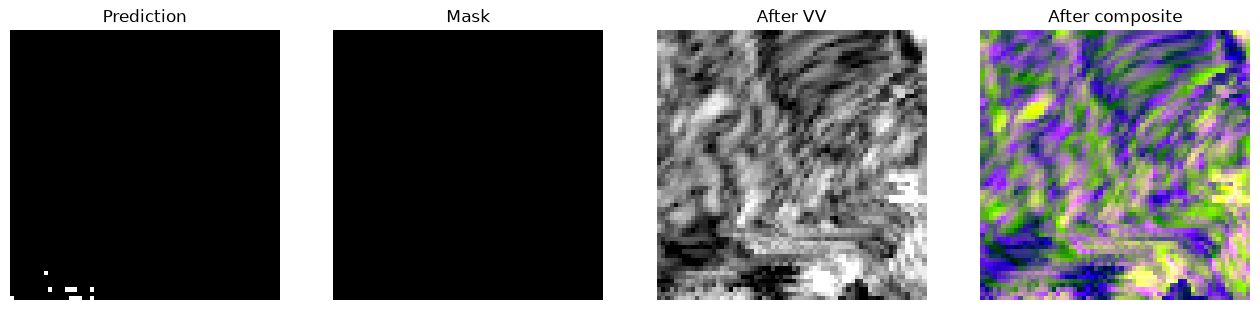

In [91]:
for i in range(len(preds)):
    pred = preds[0][i].permute(1, 2, 0).numpy().astype(np.float32)
    pred_binary = (pred > 0.5).astype(np.float32)
    mask = batch["mask"][i, 0].numpy()

    after = batch["image"][i, 1].permute(1, 2, 0).numpy().astype(np.float32)  # (H, W, 2)
    after_db = to_db(after)

    after_vv = stretch_percentile(after_db[:, :, 1])
    after_rgb = composite(after_db)

    fig, ax = plt.subplots(1, 4, figsize=(16, 4))
    ax[0].imshow(pred_binary[:, :, 0], cmap="gray"); ax[0].set_title("Prediction")
    ax[1].imshow(mask, cmap="gray");                 ax[1].set_title("Mask")
    ax[2].imshow(after_vv, cmap="gray");             ax[2].set_title("After VV")
    ax[3].imshow(after_rgb);                         ax[3].set_title("After composite")

    for a in ax:
        a.axis("off")
    plt.show()
